# Module 2 — Classification Modeling (Accident Severity Prediction)

**Project:** Traffic Accident Severity Prediction — US Accidents (2016–2023)
**DAP391m (AI & Data Science with Python & SQL) | Fall 2026 — Lớp AI2003**
**Nhóm:** Group 7 — Lê Huy Hùng (SE204967) · Nguyễn Thiện Nhân (SE203924) · Đặng Gia Bảo (SE203977)
**Giảng viên:** Lê Nhật Tùng

---

### Mục tiêu (RQ1 · RQ2 · RQ3)
Xây dựng và so sánh các mô hình phân loại để **dự báo mức độ nghiêm trọng của tai nạn** (`Severity` 1–4, multi-class), xác định mô hình nào chính xác nhất trên tập dữ liệu lớn (~7.7 triệu dòng), và trả lời RQ1: **điều kiện nào (thời tiết, thời điểm, hạ tầng đường, tầm nhìn) liên quan mạnh nhất tới tai nạn nghiêm trọng**, và RQ3: **bản đồ hotspot dự đoán từ mô hình trùng khớp với tai nạn thực tế bao nhiêu %, so với thống kê lịch sử đơn thuần**.

> **Input:** `cleaned_us_accidents.parquet` / `.csv` (output Module 1 — Data Understanding; dữ liệu gốc: Kaggle, Sobhan Moosavi, CC BY-NC-SA 4.0)
> **Target:** `Severity` (1–4, multi-class) → bài toán **classification**
> **Model:** 2 gradient boosting — **LightGBM · XGBoost**
>

## 0. Môi trường

Chạy cell dưới **một lần** nếu chưa có thư viện. Lưu ý phiên bản: `xgboost>=2.0` (API mới: `device=`, `early_stopping_rounds` trong constructor).

In [1]:
import xgboost, lightgbm, sklearn
print('xgboost  :', xgboost.__version__)   # dùng sklearn estimator API hiện hành
print('lightgbm :', lightgbm.__version__)
print('sklearn  :', sklearn.__version__)

xgboost  : 3.4.1
lightgbm : 4.7.0
sklearn  : 1.9.1


## 1. Setup & Load dữ liệu đã làm sạch

Đọc trực tiếp `cleaned_us_accidents.parquet` (hoặc `.csv` nếu không có) — output của Module 1

In [2]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titleweight'] = 'bold'
RANDOM_STATE = 42

try:
    df = pd.read_parquet('cleaned_us_accidents.parquet')   # nhanh hơn, giữ nguyên kiểu dữ liệu
except Exception:
    df = pd.read_csv('cleaned_us_accidents.csv')
print(f'Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded: 7,606,833 rows x 52 columns


## 2. Feature Engineering & chống Data Leakage

### Lưu ý quan trọng về Data Leakage
Một số cột trong US Accidents **chỉ tồn tại SAU khi tai nạn đã xảy ra và đã được đánh giá mức độ nghiêm trọng** — dùng chúng làm feature là "gian lận" (model học ngược từ hệ quả):

| Cột bị loại | Lý do leakage |
|---|---|
| `End_Time` | Thời điểm hết ảnh hưởng giao thông → tai nạn nặng thì kéo dài hơn |
| `Duration` (End−Start) | Hệ quả trực tiếp của severity, không phải nguyên nhân |
| `Distance(mi)` | Chiều dài đoạn đường bị ảnh hưởng — chính là *thước đo mức ảnh hưởng*, tương quan gần như định nghĩa với Severity |
| `End_Lat/End_Lng`, `Description` | Ghi nhận sau sự kiện / chứa text mô tả mức độ — đã loại ngay từ Module 1 |
| `Severity_high` | Cột nhị phân suy trực tiếp từ `Severity` (≥ 3) — chính là target |
| `ID` | Chỉ là mã định danh, không mang thông tin dự đoán |

Feature giữ lại đều là **thông tin có được TRƯỚC/NGAY TẠI thời điểm tai nạn**: thời tiết, thời gian, hạ tầng đường, vị trí.

>

In [3]:
# Feature engineering đã làm xong ở Module 1 (Bước 5): hour, dayofweek, month, year, season,
# is_weekend, is_rush_hour, weather_group, infra_count, is_night, low_visibility, high_wind.
# Ở đây chỉ khai báo danh sách cột hạ tầng và ghi lại các cột KHÔNG được dùng làm feature.
INFRA = ['Amenity','Bump','Crossing','Give_Way','Junction','No_Exit','Railway',
         'Roundabout','Station','Stop','Traffic_Calming','Traffic_Signal']

EXCLUDED_COLS = ['End_Time', 'Distance(mi)', 'Severity_high', 'ID']   # 3 cột đầu: leakage; ID: chỉ để định danh
print('Không dùng làm feature:', EXCLUDED_COLS)
print('Shape:', df.shape)
df[['Severity','hour','weather_group','infra_count','is_night','Visibility(mi)']].head()

Không dùng làm feature: ['End_Time', 'Distance(mi)', 'Severity_high', 'ID']
Shape: (7606833, 52)


,Severity,hour,weather_group,infra_count,is_night,Visibility(mi)
0,3,5,Rain,0,1,10.0
1,2,6,Rain,0,1,10.0
2,2,6,Cloudy,1,1,10.0
3,3,7,Cloudy,0,1,9.0
4,2,7,Cloudy,1,0,6.0


In [4]:
# Tập feature cuối cùng — đồng bộ với Module 1 (giữ Precipitation 28.51% + xóa Wind_Chill do trùng Temperature)
NUM_FEATURES = [
    'Start_Lat', 'Start_Lng',
    'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
    'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
    'hour', 'dayofweek', 'month', 'year', 'season',
    'is_weekend', 'is_rush_hour', 'is_night',
    'low_visibility', 'high_wind', 'precip_missing',
    'infra_count'
] + INFRA

CAT_FEATURES = ['State', 'Timezone', 'weather_group', 'Sunrise_Sunset', 'Civil_Twilight']
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = 'Severity'

for c in CAT_FEATURES:
    df[c] = df[c].astype('object').fillna('Unknown').astype(str)

# [SYNC Module1 40% patch] Nếu chạy với file cleaned cũ (chưa có 2 cột này), tự tạo để không KeyError
if 'Precipitation(in)' not in df.columns:
    df['Precipitation(in)'] = 0.0
if 'precip_missing' not in df.columns:
    df['precip_missing'] = 0
    df['precip_missing'] = df['precip_missing'].astype('int8')

X = df[FEATURES].copy()
y = df[TARGET].astype('int8')

print(f'Số features: {len(FEATURES)}  (numeric {len(NUM_FEATURES)} + categorical {len(CAT_FEATURES)})')
print(f'Số lớp target: {y.nunique()} -> {sorted(y.unique())}')


Số features: 37  (numeric 32 + categorical 5)
Số lớp target: 4 -> [np.int8(1), np.int8(2), np.int8(3), np.int8(4)]


## 3. Cramér's V — chuẩn bị cho RQ1



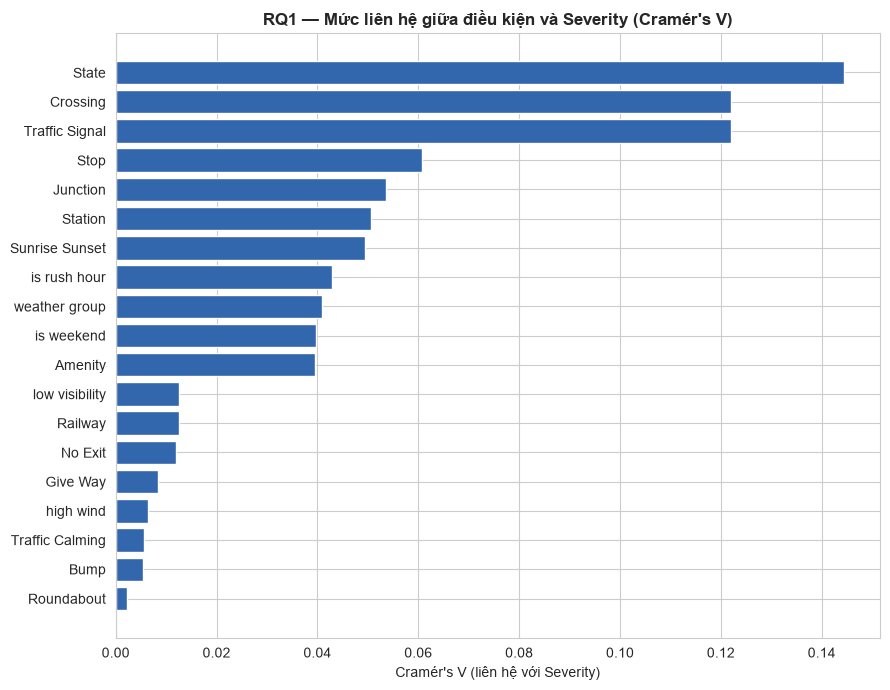

Top 8 Cramér's V:
State             0.1443
Crossing          0.1220
Traffic_Signal    0.1220
Stop              0.0608
Junction          0.0536
Station           0.0506
Sunrise_Sunset    0.0494
is_rush_hour      0.0428
dtype: float64


In [5]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    # bias correction (Bergsma 2013)
    phi2c = max(0, phi2 - (k-1)*(r-1)/(n-1))
    rc = r - (r-1)**2/(n-1)
    kc = k - (k-1)**2/(n-1)
    return np.sqrt(phi2c / max(1e-12, min(kc-1, rc-1)))

cat_for_rq1 = (['weather_group', 'Sunrise_Sunset', 'State', 'low_visibility',
                'is_rush_hour', 'is_weekend', 'high_wind'] + INFRA)

cv = {c: cramers_v(df[c], y) for c in cat_for_rq1}
cv_s = pd.Series(cv).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(range(len(cv_s)), cv_s.values[::-1], color='#3266ad')
ax.set_yticks(range(len(cv_s)))
ax.set_yticklabels([c.replace('_', ' ') for c in cv_s.index[::-1]])
ax.set_xlabel("Cramér's V (liên hệ với Severity)")
ax.set_title("RQ1 — Mức liên hệ giữa điều kiện và Severity (Cramér's V)")
plt.tight_layout(); plt.savefig('clf_cramers_v.png', dpi=150, bbox_inches='tight'); plt.show()

print("Top 8 Cramér's V:")
print(cv_s.head(8).round(4))

In [6]:
# Odds Ratio: xác suất tai nạn NGHIÊM TRỌNG (Severity 3-4) theo từng điều kiện — RQ1
y_bin = (y >= 3).astype('int8')     # gộp nhị phân đúng như RQ1 trong Project Planning

def odds_ratio(flag):
    a = ((flag == 1) & (y_bin == 1)).sum(); b = ((flag == 1) & (y_bin == 0)).sum()
    c = ((flag == 0) & (y_bin == 1)).sum(); d = ((flag == 0) & (y_bin == 0)).sum()
    return ((a + .5) * (d + .5)) / ((b + .5) * (c + .5))

or_cols = ['low_visibility', 'is_night', 'high_wind', 'is_rush_hour',
           'is_weekend', 'Junction', 'Crossing', 'Traffic_Signal', 'Stop', 'Railway']
or_s = pd.Series({c: odds_ratio(df[c]) for c in or_cols}).sort_values(ascending=False)

print('Odds Ratio cho Severity cao (3-4), OR > 1 = làm tăng rủi ro:')
print(or_s.round(3).to_string())
print(f'\nTỉ lệ tai nạn nghiêm trọng (3-4) toàn tập: {y_bin.mean()*100:.2f}%')

Odds Ratio cho Severity cao (3-4), OR > 1 = làm tăng rủi ro:
Junction          1.581
is_weekend        1.181
high_wind         1.041
is_rush_hour      1.019
low_visibility    0.981
is_night          0.967
Railway           0.734
Traffic_Signal    0.385
Crossing          0.279
Stop              0.263

Tỉ lệ tai nạn nghiêm trọng (3-4) toàn tập: 19.65%


## 4. Encoding, Stratified Split & Class Imbalance



In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')

# --- Bản encoded dùng cho cả 2 model (LightGBM / XGBoost) ---
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.float32)
X_train_enc = X_train.copy(); X_test_enc = X_test.copy()
X_train_enc[CAT_FEATURES] = enc.fit_transform(X_train[CAT_FEATURES])
X_test_enc[CAT_FEATURES]  = enc.transform(X_test[CAT_FEATURES])
X_train_enc = X_train_enc.astype(np.float32); X_test_enc = X_test_enc.astype(np.float32)

# --- Nhãn 0-based cho LightGBM / XGBoost ---
classes_sorted = np.sort(y.unique())
cls2idx = {c: i for i, c in enumerate(classes_sorted)}
idx2cls = {i: c for c, i in cls2idx.items()}
y_train_idx = y_train.map(cls2idx).values
y_test_idx  = y_test.map(cls2idx).values
N_CLASSES = len(classes_sorted)


CLASS_WEIGHT_POWER = 0.4

def tempered_class_weight(y_idx, power=CLASS_WEIGHT_POWER):
    counts = np.bincount(y_idx, minlength=N_CLASSES).astype(float)
    w = (counts.sum() / (N_CLASSES * np.maximum(counts, 1))) ** power
    w = w / w[y_idx].mean()       # chuan hoa: trong so trung binh tren moi mau = 1
    return w

CW_ARR  = tempered_class_weight(y_train_idx)            # mang theo chi so lop 0..K-1
CLASS_W = {i: float(CW_ARR[i]) for i in range(N_CLASSES)}   # dict cho LightGBM
sw_train = CW_ARR[y_train_idx]

dist = pd.Series(y_train).value_counts(normalize=True).sort_index()
print('Phan bo lop (train) & trong so:')
for i, c in enumerate(classes_sorted):
    full = (1 / dist[c]) / N_CLASSES
    print(f'  Severity {c}: {dist[c]*100:6.2f}%  | balanced = {full:7.2f} | tempered(p={CLASS_WEIGHT_POWER}) = {CW_ARR[i]:.2f}')

# [FIX] Tach validation tu TRAIN o day (thay vi trong cell XGBoost) de ca 2 model
# dung CUNG mot tap train-fit / validation -> so sanh cong bang va khong phu thuoc thu tu chay cell.
X_tr, X_val, y_tr_idx, y_val_idx, sw_tr, sw_val = train_test_split(
    X_train_enc, y_train_idx, sw_train,
    test_size=0.15, random_state=RANDOM_STATE, stratify=y_train_idx)
print(f'Train-fit: {len(X_tr):,} | Validation (early stopping): {len(X_val):,}')

Train: 6,085,466 | Test: 1,521,367
Phan bo lop (train) & trong so:
  Severity 1:   0.86%  | balanced =   29.07 | tempered(p=0.4) = 4.83
  Severity 2:  79.49%  | balanced =    0.31 | tempered(p=0.4) = 0.79
  Severity 3:  17.01%  | balanced =    1.47 | tempered(p=0.4) = 1.46
  Severity 4:   2.64%  | balanced =    9.47 | tempered(p=0.4) = 3.08
Train-fit: 5,172,646 | Validation (early stopping): 912,820


In [8]:
# Hàm đánh giá dùng chung cho cả 2 model
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, classification_report)
import numpy as np

RESULTS = {}

def evaluate(name, y_true, y_pred, y_proba=None, verbose=True):
    # Chỉ giữ các chỉ số quan trọng
    res = {
        'Accuracy':        accuracy_score(y_true, y_pred),
        'Balanced Acc':    balanced_accuracy_score(y_true, y_pred),
        'F1 (macro)':      f1_score(y_true, y_pred, average='macro'),
        'F1 (weighted)':   f1_score(y_true, y_pred, average='weighted'),
        'AUC (OvR)':       np.nan
    }

    if y_proba is not None:
        try:
            res['AUC (OvR)'] = roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro')
        except Exception as e:
            print('  (AUC lỗi:', e, ')')

    RESULTS[name] = res

    if verbose:
        print(f'{name} performance:')
        for k, v in res.items():
            if v is None or (isinstance(v, float) and np.isnan(v)):
                continue
            print(f'  {k:<14} = {v:.4f}')
        print()
        print(classification_report(y_true, y_pred, digits=3))

    return res

## 5. Model 1 — **LightGBM**

In [9]:
import lightgbm as lgb
import time
from tqdm.auto import tqdm
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
N_TREES = 3000      # trần số cây (cùng XGBoost)
LR      = 0.1      # dùng chung cho mọi bước
PATIENCE = 100      # cùng XGBoost
RUN_CV  = True      # False nếu CV trên toàn bộ X_tr quá chậm

cat_idx = [X_train_enc.columns.get_loc(c) for c in CAT_FEATURES]

def make_lgbm(n_trees=N_TREES):
    return lgb.LGBMClassifier(
        objective='multiclass', num_class=N_CLASSES,
        n_estimators=n_trees, learning_rate=LR,
        max_depth=14, num_leaves=245, min_child_samples=20,
        reg_lambda=2.1899, reg_alpha=2.2358, colsample_bytree=0.8993,
        max_bin=255, bagging_fraction=0.8, bagging_freq=1,
        cat_smooth=20, cat_l2=10,
        device='cpu', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    )

def fit_es(m, X, y, w, Xv, yv, wv):
    """Early stopping theo multi_logloss có trọng số, giống XGBoost."""
    m.fit(X, y, sample_weight=w,
          eval_set=[(Xv, yv)], eval_sample_weight=[wv],
          eval_metric='multi_logloss', categorical_feature=cat_idx,
          callbacks=[lgb.early_stopping(PATIENCE, verbose=False)])
    return m

y_tr_arr, w_tr_arr = np.asarray(y_tr_idx), np.asarray(sw_tr)
t_all = time.time()

# ===== BƯỚC 1: Chọn số cây trên VAL (early stopping) =====
m_val = fit_es(make_lgbm(), X_tr, y_tr_arr, w_tr_arr,
               X_val, np.asarray(y_val_idx), np.asarray(sw_val))
print(f'[VAL] best iteration = {m_val.best_iteration_} | '
      f'val logloss = {m_val.best_score_["valid_0"]["multi_logloss"]:.4f}')

# ===== BƯỚC 2: CV5 trên TOÀN BỘ X_tr (cùng lr, cùng seed fold) =====
if RUN_CV:
    skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    f1s, iters = [], []
    for k, (tr, va) in enumerate(tqdm(list(skf.split(X_tr, y_tr_arr)), desc='CV5'), 1):
        m = fit_es(make_lgbm(), X_tr.iloc[tr], y_tr_arr[tr], w_tr_arr[tr],
                   X_tr.iloc[va], y_tr_arr[va], w_tr_arr[va])
        f1s.append(f1_score(y_tr_arr[va], m.predict(X_tr.iloc[va]), average='macro'))
        iters.append(m.best_iteration_)
        tqdm.write(f'Fold {k}: macro-F1={f1s[-1]:.4f} | best iter={iters[-1]}')
    print(f'[CV5] macro-F1 = {np.mean(f1s):.4f} ± {np.std(f1s):.4f} | '
          f'số cây: trung vị {int(np.median(iters))}, min {min(iters)}, max {max(iters)}')

# ===== BƯỚC 3: Train lần cuối, số cây cố định, không early stopping =====
final_lgbm = make_lgbm(n_trees=m_val.best_iteration_)
final_lgbm.fit(X_tr, y_tr_arr, sample_weight=w_tr_arr, categorical_feature=cat_idx)

# ===== BƯỚC 4: Chấm TEST (chỉ một lần) =====
proba_lgb = final_lgbm.predict_proba(X_test_enc)
pred_lgb = classes_sorted[proba_lgb.argmax(axis=1)]
_ = evaluate('LightGBM', y_test, pred_lgb, proba_lgb)

print(f'Tổng thời gian: {(time.time()-t_all)/60:.1f} phút')


[VAL] best iteration = 1402 | val logloss = 0.5206


CV5:  20%|██        | 1/5 [07:01<28:06, 421.70s/it]

Fold 1: macro-F1=0.6095 | best iter=1004


CV5:  40%|████      | 2/5 [13:53<20:48, 416.09s/it]

Fold 2: macro-F1=0.6101 | best iter=912


CV5:  60%|██████    | 3/5 [20:48<13:50, 415.45s/it]

Fold 3: macro-F1=0.6132 | best iter=1013


CV5:  80%|████████  | 4/5 [28:10<07:05, 425.81s/it]

Fold 4: macro-F1=0.6109 | best iter=1046


CV5: 100%|██████████| 5/5 [34:58<00:00, 419.60s/it]


Fold 5: macro-F1=0.6097 | best iter=996
[CV5] macro-F1 = 0.6107 ± 0.0014 | số cây: trung vị 1004, min 912, max 1046
LightGBM performance:
  Accuracy       = 0.8449
  Balanced Acc   = 0.6451
  F1 (macro)     = 0.6188
  F1 (weighted)  = 0.8463
  AUC (OvR)      = 0.9214

              precision    recall  f1-score   support

           1      0.479     0.673     0.560     13083
           2      0.916     0.898     0.907   1209396
           3      0.623     0.688     0.654    258716
           4      0.397     0.321     0.355     40172

    accuracy                          0.845   1521367
   macro avg      0.604     0.645     0.619   1521367
weighted avg      0.849     0.845     0.846   1521367

Tổng thời gian: 54.1 phút


## 6. Model 2 — **XGBoost**



In [10]:
from xgboost import XGBClassifier
N_TREES = 3000

def make_xgb(n_trees=N_TREES, early_stop=None):
    return XGBClassifier(
        objective='multi:softprob', num_class=N_CLASSES,
        n_estimators=n_trees, learning_rate=0.2852, max_depth=7, max_bin=256,
        min_child_weight=7, subsample=0.7139, colsample_bytree=0.8812,
        gamma=1.4545, reg_lambda=0.3997, reg_alpha=0.0975,
        tree_method='hist', device='cuda', eval_metric='mlogloss',
        early_stopping_rounds=early_stop,
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    )

t_all = time.time()

# ===== BƯỚC 1: Chọn số cây trên VAL (early stopping, trần 3000 cây) =====
m_val = make_xgb(early_stop=100)
m_val.fit(X_tr, y_tr_idx, sample_weight=sw_tr,
          eval_set=[(X_val, y_val_idx)], sample_weight_eval_set=[sw_val], verbose=False)
print(f'[VAL] best iteration = {m_val.best_iteration + 1} | val logloss = {m_val.best_score:.4f}')

# ===== BƯỚC 2: CV5 trên TRAIN (kiểm tra độ ổn định của số cây) =====
Xf, yf, swf = map(np.asarray, (X_tr, y_tr_idx, sw_tr))
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
f1s, iters = [], []
for k, (tr, va) in enumerate(tqdm(list(skf.split(Xf, yf)), desc='CV5'), 1):
    m = make_xgb(early_stop=100)
    m.fit(Xf[tr], yf[tr], sample_weight=swf[tr],
          eval_set=[(Xf[va], yf[va])], sample_weight_eval_set=[swf[va]], verbose=False)
    f1s.append(f1_score(yf[va], m.predict(Xf[va]), average='macro'))
    iters.append(m.best_iteration + 1)
    tqdm.write(f'Fold {k}: macro-F1={f1s[-1]:.4f} | best iter={iters[-1]}')
print(f'[CV5] macro-F1 = {np.mean(f1s):.4f} ± {np.std(f1s):.4f} | '
      f'số cây: trung vị {int(np.median(iters))}, min {min(iters)}, max {max(iters)}')

# ===== BƯỚC 3: Train lần cuối, cố định 3000 cây, không early stopping =====
final_xgb  = make_xgb(n_trees=m_val.best_iteration + 1)
final_xgb.fit(X_tr, y_tr_idx, sample_weight=sw_tr, verbose=False)

# ===== BƯỚC 4: Chấm TEST (chỉ chạm một lần) =====
proba_xgb = final_xgb.predict_proba(X_test_enc)
pred_xgb = classes_sorted[proba_xgb.argmax(axis=1)]
_ = evaluate('XGBoost', y_test, pred_xgb, proba_xgb)

print(f'Tổng thời gian: {(time.time()-t_all)/60:.1f} phút')


[VAL] best iteration = 1941 | val logloss = 0.5379


CV5:  20%|██        | 1/5 [02:07<08:28, 127.00s/it]

Fold 1: macro-F1=0.5955 | best iter=1460


CV5:  40%|████      | 2/5 [04:04<06:03, 121.16s/it]

Fold 2: macro-F1=0.5970 | best iter=1320


CV5:  60%|██████    | 3/5 [06:04<04:01, 120.81s/it]

Fold 3: macro-F1=0.5967 | best iter=1360


CV5:  80%|████████  | 4/5 [08:05<02:01, 121.01s/it]

Fold 4: macro-F1=0.5949 | best iter=1387


CV5: 100%|██████████| 5/5 [09:51<00:00, 118.20s/it]


Fold 5: macro-F1=0.5930 | best iter=1152
[CV5] macro-F1 = 0.5954 ± 0.0014 | số cây: trung vị 1360, min 1152, max 1460
XGBoost performance:
  Accuracy       = 0.8385
  Balanced Acc   = 0.6439
  F1 (macro)     = 0.6041
  F1 (weighted)  = 0.8407
  AUC (OvR)      = 0.9149

              precision    recall  f1-score   support

           1      0.434     0.695     0.535     13083
           2      0.915     0.892     0.903   1209396
           3      0.611     0.678     0.643    258716
           4      0.365     0.311     0.336     40172

    accuracy                          0.838   1521367
   macro avg      0.581     0.644     0.604   1521367
weighted avg      0.844     0.838     0.841   1521367

Tổng thời gian: 16.1 phút


## 7. So sánh 2 Model & Đánh giá (RQ2)

In [11]:
# Bảng so sánh 2 mô hình


comparison = pd.DataFrame(RESULTS).T


comparison = comparison[[
    'Accuracy',
    'Balanced Acc',
    'F1 (macro)',
    'F1 (weighted)',
    'AUC (OvR)'
]].astype(float).round(4)

# Sắp xếp theo F1 macro giảm dần — ưu tiên phát hiện tai nạn nặng
comparison = comparison.sort_values('F1 (macro)', ascending=False)

# In ra màn hình
print(comparison.to_string())

# Chọn mô hình tốt nhất
BEST_MODEL = comparison.index[0]
print(f'\n Mô hình tốt nhất theo F1 (macro): {BEST_MODEL}')

# Lưu ra file để nộp/báo cáo
comparison.to_csv('clf_model_comparison.csv')
print('\nĐã lưu kết quả vào: clf_model_comparison.csv')

          Accuracy  Balanced Acc  F1 (macro)  F1 (weighted)  AUC (OvR)
LightGBM    0.8449        0.6451      0.6188         0.8463     0.9214
XGBoost     0.8385        0.6439      0.6041         0.8407     0.9149

 Mô hình tốt nhất theo F1 (macro): LightGBM

Đã lưu kết quả vào: clf_model_comparison.csv


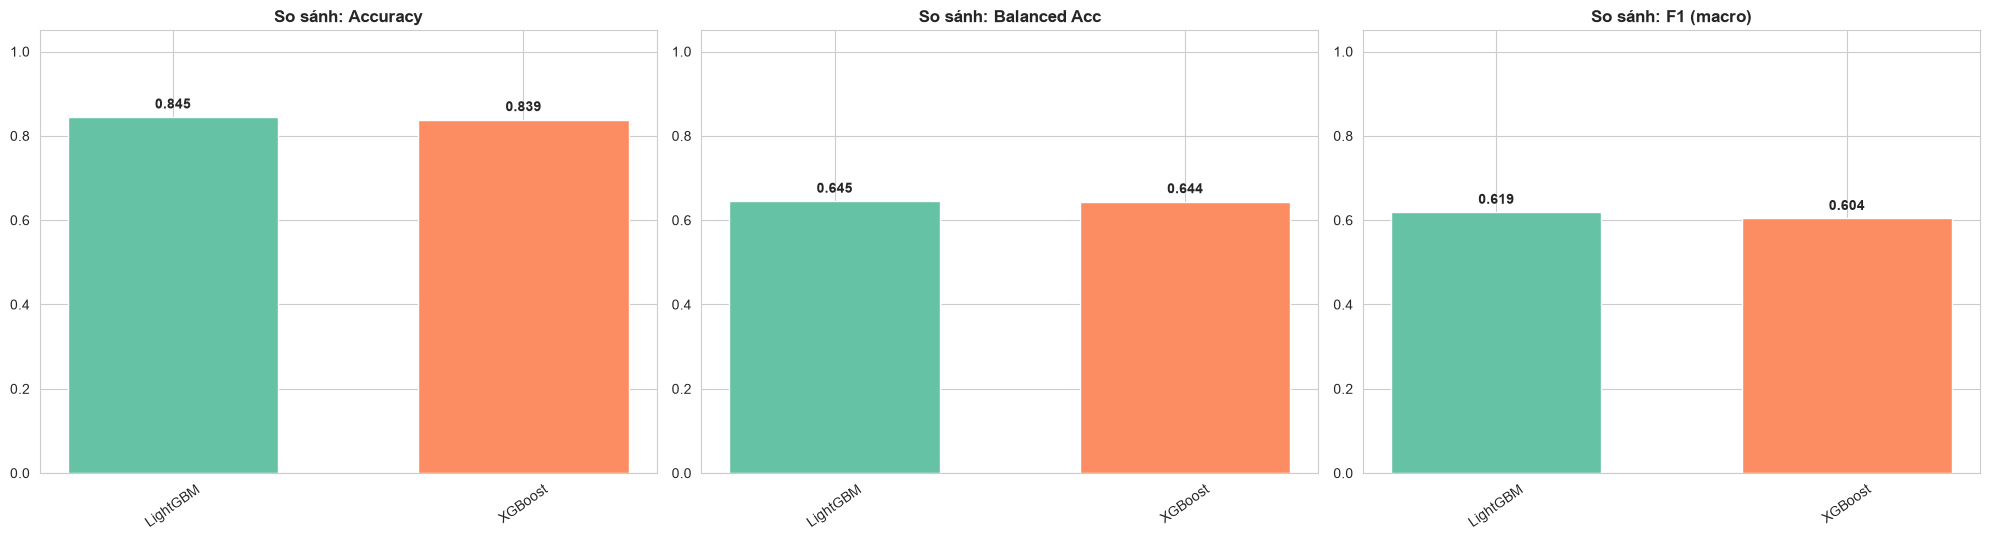

In [12]:
order = list(comparison.index)
cmp_o = comparison.loc[order]


colors_m = sns.color_palette('Set2', len(order))

# --- Biểu đồ so sánh ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for ax, metric, fmt in zip(axes,
                           ['Accuracy', 'Balanced Acc', 'F1 (macro)'],
                           ['{:.3f}', '{:.3f}', '{:.3f}']):
    vals = cmp_o[metric].values
    bars = ax.bar(order, vals, color=colors_m, width=0.6)
    ax.set_title(f'So sánh: {metric}')
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', rotation=35)

    for b, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width()/2, v + 0.02,
                    fmt.format(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Confusion Matrix & ROC one-vs-rest (model tốt nhất)

RQ3 recovery cache saved: rq3_context.npz


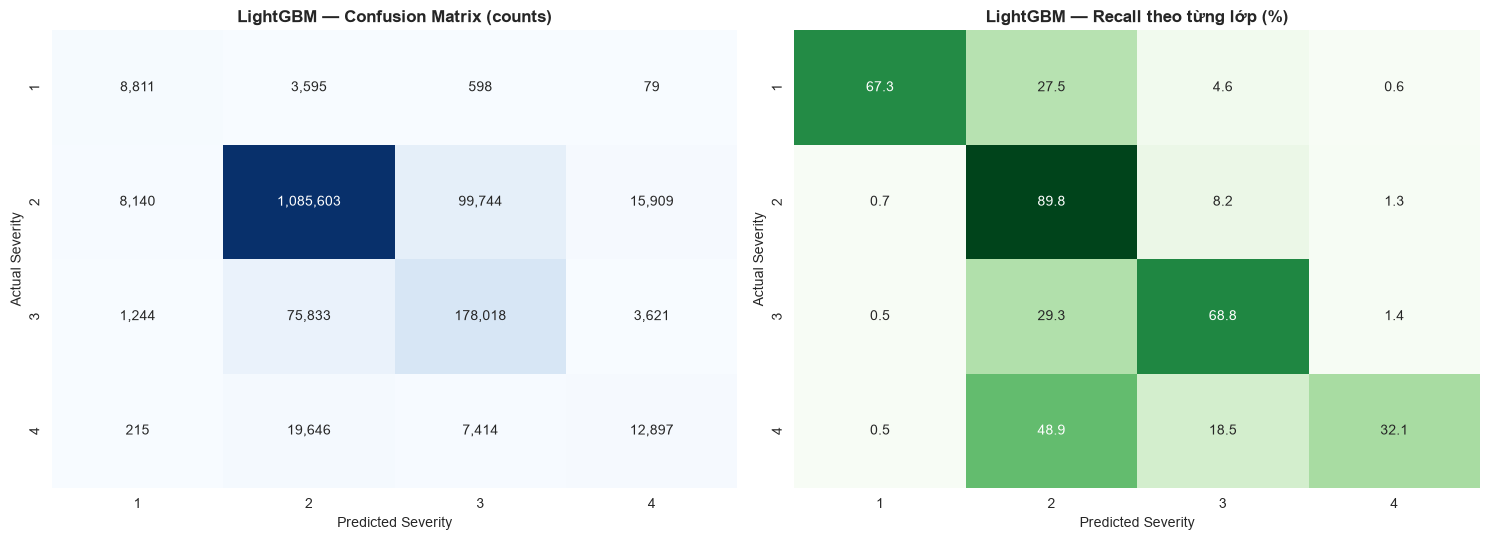

In [13]:
from sklearn.metrics import confusion_matrix
PREDS  = {'XGBoost': pred_xgb,  'LightGBM': pred_lgb}
PROBAS = {'XGBoost': proba_xgb, 'LightGBM': proba_lgb}

best_pred, best_proba = PREDS[BEST_MODEL], PROBAS[BEST_MODEL]

# Cache compact RQ3 inputs so the hotspot analysis can recover after a kernel restart.
# The cache contains only coordinates, true labels, model probabilities, and model metadata.
RQ3_CACHE = 'rq3_context.npz'
np.savez_compressed(
    RQ3_CACHE,
    train_lat=X_train['Start_Lat'].to_numpy(dtype=np.float32),
    train_lng=X_train['Start_Lng'].to_numpy(dtype=np.float32),
    train_y=y_train.to_numpy(dtype=np.int8),
    test_lat=X_test['Start_Lat'].to_numpy(dtype=np.float32),
    test_lng=X_test['Start_Lng'].to_numpy(dtype=np.float32),
    test_y=y_test.to_numpy(dtype=np.int8),
    best_proba=np.asarray(best_proba, dtype=np.float32),
    best_model=np.asarray(BEST_MODEL),
    classes_sorted=np.asarray(classes_sorted, dtype=np.int8),
)
print(f'RQ3 recovery cache saved: {RQ3_CACHE}')

# === Tính ma trận nhầm lẫn ===
cm = confusion_matrix(y_test, best_pred, labels=classes_sorted)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

# === Vẽ biểu đồ ===
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=classes_sorted, yticklabels=classes_sorted, ax=axes[0])
axes[0].set_title(f'{BEST_MODEL} — Confusion Matrix (counts)')
axes[0].set_xlabel('Predicted Severity')
axes[0].set_ylabel('Actual Severity')

sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Greens', cbar=False,
            xticklabels=classes_sorted, yticklabels=classes_sorted, ax=axes[1])
axes[1].set_title(f'{BEST_MODEL} — Recall theo từng lớp (%)')
axes[1].set_xlabel('Predicted Severity')
axes[1].set_ylabel('Actual Severity')

plt.tight_layout()
plt.savefig('clf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

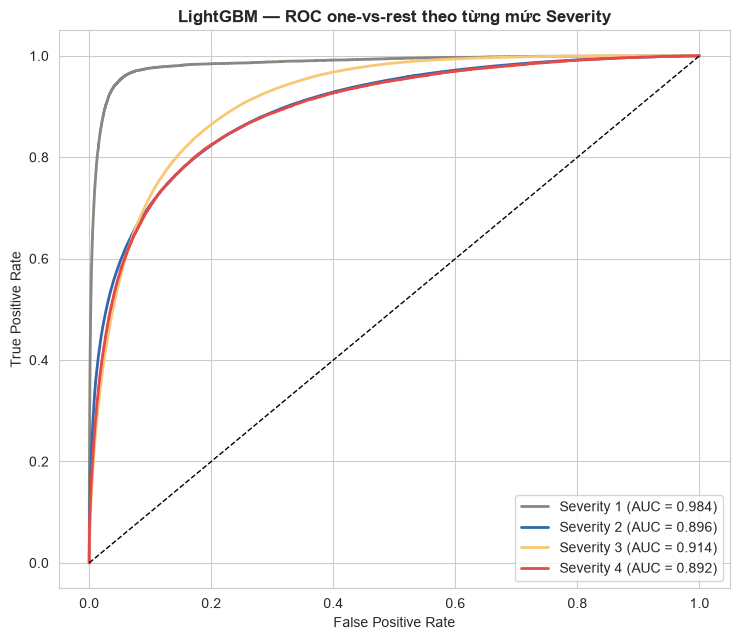

In [14]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test, classes=classes_sorted)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
palette = ['#888780', '#3266ad', '#FAC775', '#E24B4A']
for i, cls in enumerate(classes_sorted):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], best_proba[:, i])
    ax.plot(fpr, tpr, lw=2, color=palette[i % 4],
            label=f'Severity {cls} (AUC = {auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title(f'{BEST_MODEL} — ROC one-vs-rest theo từng mức Severity')
ax.legend(loc='lower right'); plt.tight_layout()
plt.savefig('clf_roc_ovr.png', dpi=150, bbox_inches='tight'); plt.show()

## 9. Feature Importance — Yếu tố nào drive Severity? (RQ1)

Ưu tiên **SHAP** (`TreeExplainer`) vì nó cho biết cả độ mạnh **và hướng** tác động, lại ít bị lệch bởi đa cộng tuyến đã phát hiện ở phần 3.

> Chạy trên mẫu 20k dòng test cho nhanh; tăng `SHAP_N` nếu cần độ mịn.

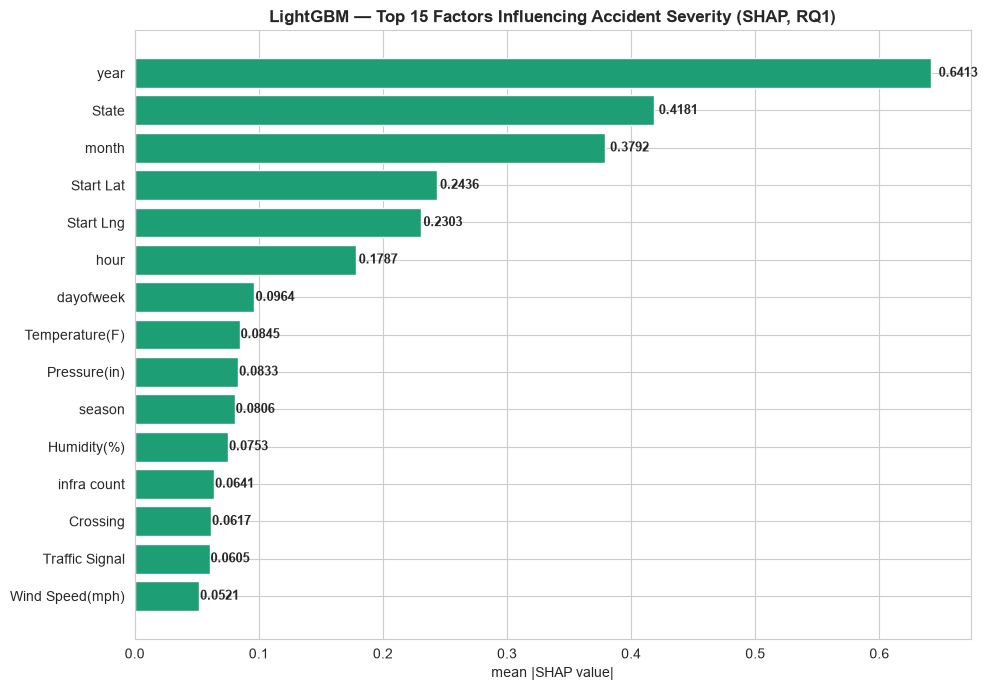

Top 8 drivers of Severity (SHAP):
  year                   0.6413
  State                  0.4181
  month                  0.3792
  Start_Lat              0.2436
  Start_Lng              0.2303
  hour                   0.1787
  dayofweek              0.0964
  Temperature(F)         0.0845

Importance gộp theo nhóm biến (%):
Thời gian        47.7 %
Vị trí           29.9 %
Thời tiết        13.4 %
Hạ tầng đường     9.0 %


In [23]:
SHAP_N = 20_000
shap_sample = X_test_enc.sample(min(SHAP_N, len(X_test_enc)), random_state=RANDOM_STATE)
# Sử dụng các mô hình đã lưu tên là final_xgb và final_lgbm
best_obj = {'XGBoost': final_xgb, 'LightGBM': final_lgbm}[BEST_MODEL]

import shap
explainer = shap.TreeExplainer(best_obj)
shap_values = explainer.shap_values(shap_sample)

shap_arr = np.array(shap_values)
# Chuẩn hoá shape về (n_samples, n_features, n_classes) rồi lấy mean |SHAP| qua các lớp
if shap_arr.ndim == 3 and shap_arr.shape[0] == N_CLASSES:
    shap_arr = np.transpose(shap_arr, (1, 2, 0))
mean_abs = (np.abs(shap_arr).mean(axis=(0, 2)) if shap_arr.ndim == 3
            else np.abs(shap_arr).mean(axis=0))
imp = pd.Series(mean_abs, index=shap_sample.columns).sort_values(ascending=False)
IMP_LABEL = 'mean |SHAP value|'
IMP_METHOD = 'SHAP'

top15 = imp.head(15)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(top15)), top15.values[::-1], color='#1D9E75')
ax.set_yticks(range(len(top15)))
ax.set_yticklabels([f.replace('_', ' ') for f in top15.index[::-1]])
ax.set_xlabel(IMP_LABEL)
ax.set_title(f'{BEST_MODEL} — Top 15 Factors Influencing Accident Severity ({IMP_METHOD}, RQ1)')
for i, v in enumerate(top15.values[::-1]):
    ax.text(v*1.01, i, f'{v:.4f}', va='center', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.savefig('clf_feature_importance.png', dpi=150, bbox_inches='tight'); plt.show()

print(f'Top 8 drivers of Severity ({IMP_METHOD}):')
for f, v in imp.head(8).items():
    print(f'  {f:<22} {v:.4f}')

# Gộp importance theo nhóm biến — tiện viết Discussion
GROUPS = {
    'Vị trí':        ['Start_Lat', 'Start_Lng', 'State', 'Timezone'],
    'Thời tiết':     ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Precipitation(in)', 'precip_missing',
                      'Wind_Speed(mph)', 'weather_group',
                      'low_visibility', 'high_wind'],
    'Thời gian':     ['hour', 'dayofweek', 'month', 'year', 'season', 'is_weekend',
                      'is_rush_hour', 'is_night', 'Sunrise_Sunset', 'Civil_Twilight'],
    'Hạ tầng đường': INFRA + ['infra_count'],
}
imp_pos = imp.clip(lower=0)
grouped = pd.Series({g: imp_pos[[c for c in cols if c in imp_pos.index]].sum()
                     for g, cols in GROUPS.items()}).sort_values(ascending=False)
print('\nImportance gộp theo nhóm biến (%):')
print((grouped / grouped.sum() * 100).round(1).astype(str).add(' %').to_string())


> ⚠️ **Các con số dưới đây lấy từ lần chạy với dữ liệu Module 1 phiên bản cũ** (còn `Precipitation`, `high_wind` chưa chuẩn). Sau khi chạy lại toàn bộ notebook, hãy cập nhật các số (nhóm biến %, SHAP, Odds Ratio) và kiểm tra các nhận xét còn đúng không.

**Nhận xét RQ1 (số thật từ SHAP của LightGBM, mẫu 20k dòng test):**

Importance gộp theo nhóm biến: **Thời gian 47.9% · Vị trí 31.8% · Thời tiết 11.1% · Hạ tầng đường 9.2%**.

1. **`year` là feature mạnh nhất (0.6342)** — đây là **cảnh báo data drift**, không phải phát hiện khoa học. Cách MapQuest/Bing gán nhãn `Severity` thay đổi qua các năm, nên model đang học "vụ này thuộc năm nào" thay vì "điều kiện gì gây nặng". Bắt buộc phải ghi vào Limitations; muốn sạch thì bỏ `year` rồi train lại và so kết quả.
2. **Vị trí đứng thứ hai** (`State` 0.5094, `Start_Lat` 0.2622, `Start_Lng` 0.2017) → severity phụ thuộc mạnh vào bối cảnh địa lý / loại đường (highway vs nội thị). Đây chính là cầu nối sang RQ3 (hotspot).
3. **Thời tiết chỉ 11.1%** — thấp hơn nhiều so với trực giác. Rất đáng viết vào Discussion, vì hầu hết người đọc mặc định thời tiết là yếu tố số 1.
4. **Hạ tầng đường thấp nhất (9.2%) nhưng có hướng rõ ràng**: Odds Ratio ở phần 3 cho `Traffic_Signal` 0.391, `Crossing` 0.284, `Stop` 0.268 — tức chỗ có đèn/vạch/biển dừng làm **giảm** mức nghiêm trọng (xe buộc chạy chậm), còn `Junction` 1.573 và `high_wind` 4.138 làm **tăng**. Kết quả phản trực giác này là điểm mạnh của báo cáo.
5. **Correlation ≠ causation:** `high_wind` OR = 4.14 không có nghĩa gió to *gây ra* tai nạn nặng — gió mạnh thường đi cùng đường cao tốc trống trải, tốc độ cao. Biến gây nhiễu thật là **tốc độ giới hạn**, mà dataset này **không có**.

## 10. RQ3 — Bản đồ hotspot dự đoán vs thống kê lịch sử

### Câu hỏi
> *Bản đồ điểm nóng tai nạn (hotspot) dự đoán bằng mô hình có trùng khớp với vị trí tai nạn thực tế bao nhiêu %, so với thống kê lịch sử đơn thuần?*

In [16]:
import matplotlib.colors as mcolors     # dung cho thang mau log o ban do

# Neu kernel vua restart, nap lai cache tao o PHAN 9 - Confusion Matrix (sau khi chon model).
_need = ['X_train', 'y_train', 'X_test', 'y_test', 'best_proba', 'BEST_MODEL', 'classes_sorted']
_missing = [v for v in _need if v not in globals()]
if _missing:
    if not os.path.exists('rq3_context.npz'):
        raise RuntimeError(
            "RQ3 chua co du lieu trong RAM va khong tim thay rq3_context.npz. "
            "Chay notebook tu dau den het phan 9 (Confusion Matrix) de tao cache, "
            "sau do co the chay lai RQ3 sau khi restart kernel."
        )
    _rq3 = np.load('rq3_context.npz', allow_pickle=False)
    X_train = pd.DataFrame({'Start_Lat': _rq3['train_lat'], 'Start_Lng': _rq3['train_lng']})
    y_train = pd.Series(_rq3['train_y'])
    X_test = pd.DataFrame({'Start_Lat': _rq3['test_lat'], 'Start_Lng': _rq3['test_lng']})
    y_test = pd.Series(_rq3['test_y'])
    best_proba = _rq3['best_proba']
    BEST_MODEL = str(_rq3['best_model'].item())
    classes_sorted = _rq3['classes_sorted']
    print('Da nap lai du lieu RQ3 tu rq3_context.npz')
else:
    print('Da co du bien RQ2 trong RAM ->', BEST_MODEL)

# ============================================
# RQ3 - Buoc 1: xay dung luoi (grid) va tong hop 3 ban do
# ============================================
GRID_DEG = 0.1            # kich thuoc o luoi (do); 0.1 do ~ 11 km
TOP_K    = 200            # so o duoc coi la "hotspot"
LAT_MIN, LAT_MAX = 24.0, 50.0        # gioi han CONUS (48 bang lien ke)
LNG_MIN, LNG_MAX = -125.0, -66.0
_OFF = 4000               # offset de khoa o luoi khong bi trung khi bin am

# Cot xac suat cua cac lop nghiem trong (Severity 3 va 4) trong best_proba
sev_pos = [i for i, c in enumerate(classes_sorted) if c >= 3]
print(f'Cot xac suat nghiem trong: Severity {[int(classes_sorted[i]) for i in sev_pos]}')

def _conus(d):
    m = d['lat'].between(LAT_MIN, LAT_MAX) & d['lng'].between(LNG_MIN, LNG_MAX)
    return d.loc[m].copy()

# --- TAP TEST: su that (actual) + du doan cua model (out-of-sample) ---
test_base = _conus(pd.DataFrame({
    'lat':           X_test['Start_Lat'].to_numpy(dtype=np.float32),
    'lng':           X_test['Start_Lng'].to_numpy(dtype=np.float32),
    'actual_severe': (y_test.to_numpy() >= 3).astype(np.int8),
    'prob_severe':   best_proba[:, sev_pos].sum(axis=1).astype(np.float32),
}))

# --- TAP TRAIN: thong ke lich su don thuan (baseline, KHONG dung model) ---
train_base = _conus(pd.DataFrame({
    'lat':         X_train['Start_Lat'].to_numpy(dtype=np.float32),
    'lng':         X_train['Start_Lng'].to_numpy(dtype=np.float32),
    'hist_severe': (y_train.to_numpy() >= 3).astype(np.int8),
}))
print(f'Diem trong CONUS: test {len(test_base):,} | train {len(train_base):,}')

def _mkkey(lat_bin, lng_bin):
    """Ghep (lat_bin, lng_bin) thanh mot khoa int64 duy nhat cho moi o luoi."""
    return (lat_bin.astype(np.int64) + _OFF) * 100_000 + (lng_bin.astype(np.int64) + _OFF)

def build_grid(deg=GRID_DEG):
    """Gan tai nan vao o luoi roi tong hop: THUC TE / MODEL / LICH SU."""
    t = test_base.assign(
        lat_bin=np.floor(test_base['lat'] / deg).astype(np.int32),
        lng_bin=np.floor(test_base['lng'] / deg).astype(np.int32))
    h = train_base.assign(
        lat_bin=np.floor(train_base['lat'] / deg).astype(np.int32),
        lng_bin=np.floor(train_base['lng'] / deg).astype(np.int32))

    g_t = (t.groupby(['lat_bin', 'lng_bin'], sort=False)
             .agg(n_test=('actual_severe', 'size'),
                  actual_severe=('actual_severe', 'sum'),
                  exp_severe=('prob_severe', 'sum'),
                  mean_prob=('prob_severe', 'mean'))
             .reset_index())
    g_h = (h.groupby(['lat_bin', 'lng_bin'], sort=False)
             .agg(n_train=('hist_severe', 'size'),
                  hist_severe=('hist_severe', 'sum'))
             .reset_index())

    g = g_t.merge(g_h, on=['lat_bin', 'lng_bin'], how='outer').fillna(0)
    g['key']   = _mkkey(g['lat_bin'].to_numpy(), g['lng_bin'].to_numpy())
    g['lat_c'] = (g['lat_bin'] + 0.5) * deg
    g['lng_c'] = (g['lng_bin'] + 0.5) * deg
    g['hist_rate'] = np.where(g['n_train'] > 0, g['hist_severe'] / g['n_train'], 0.0)
    return g

grid = build_grid(GRID_DEG)

print(f'\nSo o luoi co du lieu     : {len(grid):,}  (o {GRID_DEG} do ~ {GRID_DEG*111:.0f} km)')
print(f'Tai nan test trong luoi  : {int(grid["n_test"].sum()):,}')
print(f'Tai nan nghiem trong THAT: {int(grid["actual_severe"].sum()):,}')
print(f'Ky vong tu model         : {grid["exp_severe"].sum():,.0f}')
grid.sort_values("actual_severe", ascending=False).head()

Da co du bien RQ2 trong RAM -> LightGBM
Cot xac suat nghiem trong: Severity [3, 4]
Diem trong CONUS: test 1,521,367 | train 6,085,466

So o luoi co du lieu     : 33,669  (o 0.1 do ~ 11 km)
Tai nan test trong luoi  : 1,521,367
Tai nan nghiem trong THAT: 298,888
Ky vong tu model         : 409,208


,lat_bin,lng_bin,n_test,actual_severe,exp_severe,mean_prob,n_train,hist_severe,key,lat_c,lng_c,hist_rate
6393,337,-844,4264.0,2284.0,2683.480957,0.629334,16617.0,8988.0,433703156,33.75,-84.35,0.540892
6818,340,-1183,9898.0,2283.0,2997.699707,0.302859,39880.0,9362.0,434002817,34.05,-118.25,0.234754
21320,408,-740,5352.0,1731.0,2258.860596,0.422059,21438.0,7095.0,440803260,40.85,-73.95,0.330954
6625,339,-1182,4702.0,1566.0,1912.803711,0.406806,18948.0,6413.0,433902818,33.95,-118.15,0.338453
6816,340,-1185,3951.0,1430.0,1739.889771,0.440367,15766.0,5798.0,434002815,34.05,-118.45,0.367753


In [17]:
# ============================================
# RQ3 - Buoc 2: dinh nghia hotspot va do % chong lap (IoU / Overlap)
# ============================================
def topk_cells(g, col, k):
    """Khoa cua K o co gia tri cao nhat theo cot col."""
    return g.nlargest(k, col)['key'].to_numpy()

def iou(a, b):
    u = len(np.union1d(a, b))
    return len(np.intersect1d(a, b)) / u if u else np.nan

def overlap_pct(a, ref):
    return len(np.intersect1d(a, ref)) / len(ref) * 100 if len(ref) else np.nan

def captured_pct(g, cells, col='actual_severe'):
    """% tai nan nghiem trong THUC TE nam trong tap o cells."""
    tot = g[col].sum()
    if tot == 0:
        return np.nan
    m = np.isin(g['key'].to_numpy(), cells)
    return g.loc[m, col].sum() / tot * 100

# Ba ban do hotspot, cung TOP_K o
H_actual = topk_cells(grid, 'actual_severe', TOP_K)   # SU THAT tren tap test
H_model  = topk_cells(grid, 'exp_severe',    TOP_K)   # MODEL du doan (tong xac suat)
H_hist   = topk_cells(grid, 'hist_severe',   TOP_K)   # THONG KE LICH SU (baseline)

rq3 = pd.DataFrame([
    {'Phuong phap': f'Model ({BEST_MODEL})',
     'IoU vs thuc te':          iou(H_model, H_actual),
     'Overlap % vs thuc te':    overlap_pct(H_model, H_actual),
     '% tai nan nang bat duoc': captured_pct(grid, H_model)},
    {'Phuong phap': 'Thong ke lich su (baseline)',
     'IoU vs thuc te':          iou(H_hist, H_actual),
     'Overlap % vs thuc te':    overlap_pct(H_hist, H_actual),
     '% tai nan nang bat duoc': captured_pct(grid, H_hist)},
]).round(4)

print(f'Hotspot = TOP {TOP_K} o luoi, kich thuoc o {GRID_DEG} do (~{GRID_DEG*111:.0f} km)')
print(f'Tong so o co du lieu: {len(grid):,}\n')
print(rq3.to_string(index=False))

d_iou = rq3.loc[0, 'IoU vs thuc te']          - rq3.loc[1, 'IoU vs thuc te']
d_ovl = rq3.loc[0, 'Overlap % vs thuc te']    - rq3.loc[1, 'Overlap % vs thuc te']
d_cap = rq3.loc[0, '% tai nan nang bat duoc'] - rq3.loc[1, '% tai nan nang bat duoc']
print('\n=> MODEL so voi THONG KE LICH SU don thuan (cau tra loi truc tiep cho RQ3):')
print(f'   IoU        : {d_iou:+.4f}')
print(f'   Overlap %  : {d_ovl:+.2f} diem %')
print(f'   Bat duoc % : {d_cap:+.2f} diem %')
print('   (duong = model tot hon lich su; am/xap xi 0 = lich su da du tot)')

print(f'\nO trung nhau ca 3 ban do : {len(np.intersect1d(np.intersect1d(H_model, H_hist), H_actual))}')
print(f'O chi model chon         : {len(np.setdiff1d(H_model, H_hist))}')
print(f'O chi lich su chon       : {len(np.setdiff1d(H_hist, H_model))}')

Hotspot = TOP 200 o luoi, kich thuoc o 0.1 do (~11 km)
Tong so o co du lieu: 33,669

                Phuong phap  IoU vs thuc te  Overlap % vs thuc te  % tai nan nang bat duoc
           Model (LightGBM)          0.8519                  92.0                  39.4402
Thong ke lich su (baseline)          0.9417                  97.0                  39.7353

=> MODEL so voi THONG KE LICH SU don thuan (cau tra loi truc tiep cho RQ3):
   IoU        : -0.0898
   Overlap %  : -5.00 diem %
   Bat duoc % : -0.30 diem %
   (duong = model tot hon lich su; am/xap xi 0 = lich su da du tot)

O trung nhau ca 3 ban do : 183
O chi model chon         : 14
O chi lich su chon       : 14


### Trực quan hóa bản đồ hotspot

Phần trên mới chỉ cho ra **con số** (IoU, Overlap %, % tai nạn nặng bắt được). Các cell dưới đây vẽ **bản đồ** để nhìn trực tiếp hotspot nằm ở đâu và model khác thống kê lịch sử chỗ nào:

1. **Bản đồ mật độ** — phân bố tai nạn nghiêm trọng theo ô lưới (thang màu log): thực tế · model · lịch sử
2. **Bản đồ Top-K hotspot** — chỉ tô `TOP_K` ô nóng nhất của từng phương pháp
3. **Bản đồ trùng khớp** — ô nào dự đoán *đúng*, *thừa* (báo động giả), *bỏ sót* so với thực tế
4. **Biểu đồ so sánh + Top 10 ô nóng nhất**
5. **Bản đồ tương tác** (folium, tùy chọn) — xuất ra file HTML để zoom/bật tắt từng lớp

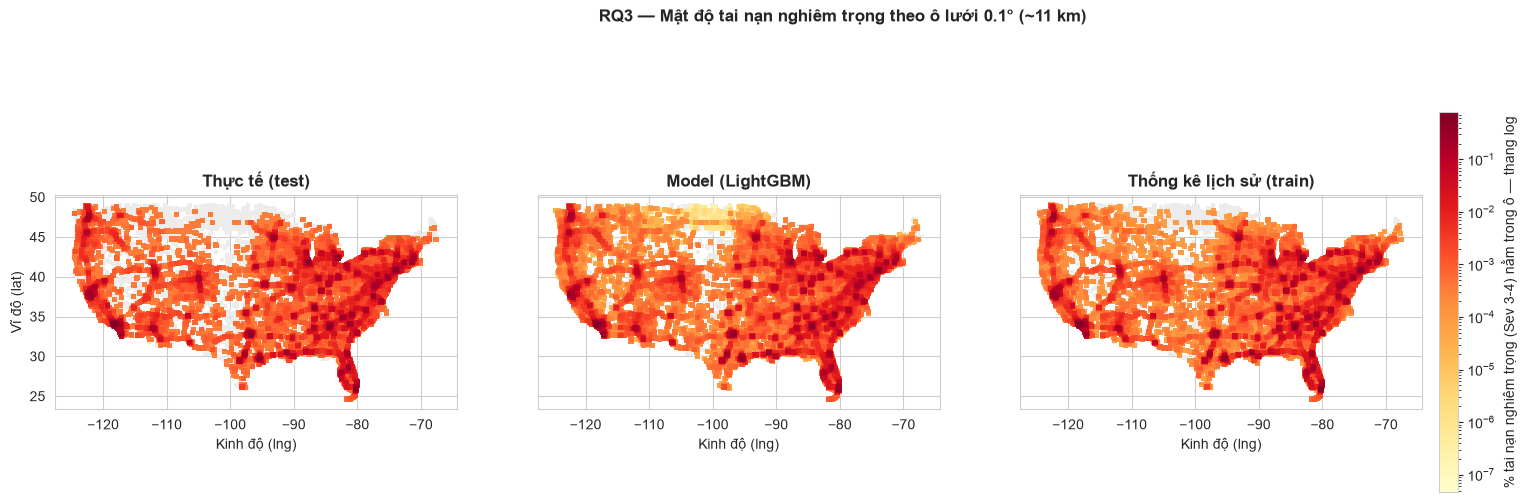

In [18]:
# ============================================
# RQ3 - Buoc 3a: Ban do MAT DO tai nan nghiem trong (thang mau log)
# ============================================
# Chia moi cot cho tong cua no -> "% tai nan nang nam trong o do", de 3 ban do so sanh duoc
# voi nhau (hist_severe dem tren TRAIN ~80% du lieu, actual_severe dem tren TEST ~20%).
ASPECT = 1 / np.cos(np.radians((LAT_MIN + LAT_MAX) / 2))     # chinh ty le lat/lng cho do meo ban do

dens = pd.DataFrame({
    'lng_c': grid['lng_c'], 'lat_c': grid['lat_c'],
    'Thực tế (test)':             grid['actual_severe'] / grid['actual_severe'].sum() * 100,
    f'Model ({BEST_MODEL})':      grid['exp_severe']    / grid['exp_severe'].sum()    * 100,
    'Thống kê lịch sử (train)':   grid['hist_severe']   / grid['hist_severe'].sum()   * 100,
})
panel_cols = [c for c in dens.columns if c not in ('lng_c', 'lat_c')]

_pos = dens[panel_cols].to_numpy()
_pos = _pos[_pos > 0]
norm = mcolors.LogNorm(vmin=_pos.min(), vmax=_pos.max())     # cung 1 thang mau cho ca 3 panel

fig, axes = plt.subplots(1, 3, figsize=(21, 5.8), sharex=True, sharey=True)
for ax, col in zip(axes, panel_cols):
    d = dens[dens[col] > 0].sort_values(col)                 # o dam ve sau cung -> khong bi che
    ax.scatter(dens['lng_c'], dens['lat_c'], c='#ececec', s=6, marker='s', linewidths=0)   # nen: hinh dang nuoc My
    sc = ax.scatter(d['lng_c'], d['lat_c'], c=d[col], cmap='YlOrRd', norm=norm,
                    s=14, marker='s', linewidths=0)
    ax.set_title(col)
    ax.set_xlabel('Kinh độ (lng)')
    ax.set_aspect(ASPECT)
axes[0].set_ylabel('Vĩ độ (lat)')
cbar = fig.colorbar(sc, ax=axes, shrink=0.85, pad=0.01)
cbar.set_label('% tai nạn nghiêm trọng (Sev 3-4) nằm trong ô — thang log')
fig.suptitle(f'RQ3 — Mật độ tai nạn nghiêm trọng theo ô lưới {GRID_DEG}° (~{GRID_DEG*111:.0f} km)',
             fontweight='bold', y=1.0)
plt.savefig('rq3_density_maps.png', dpi=150, bbox_inches='tight')
plt.show()

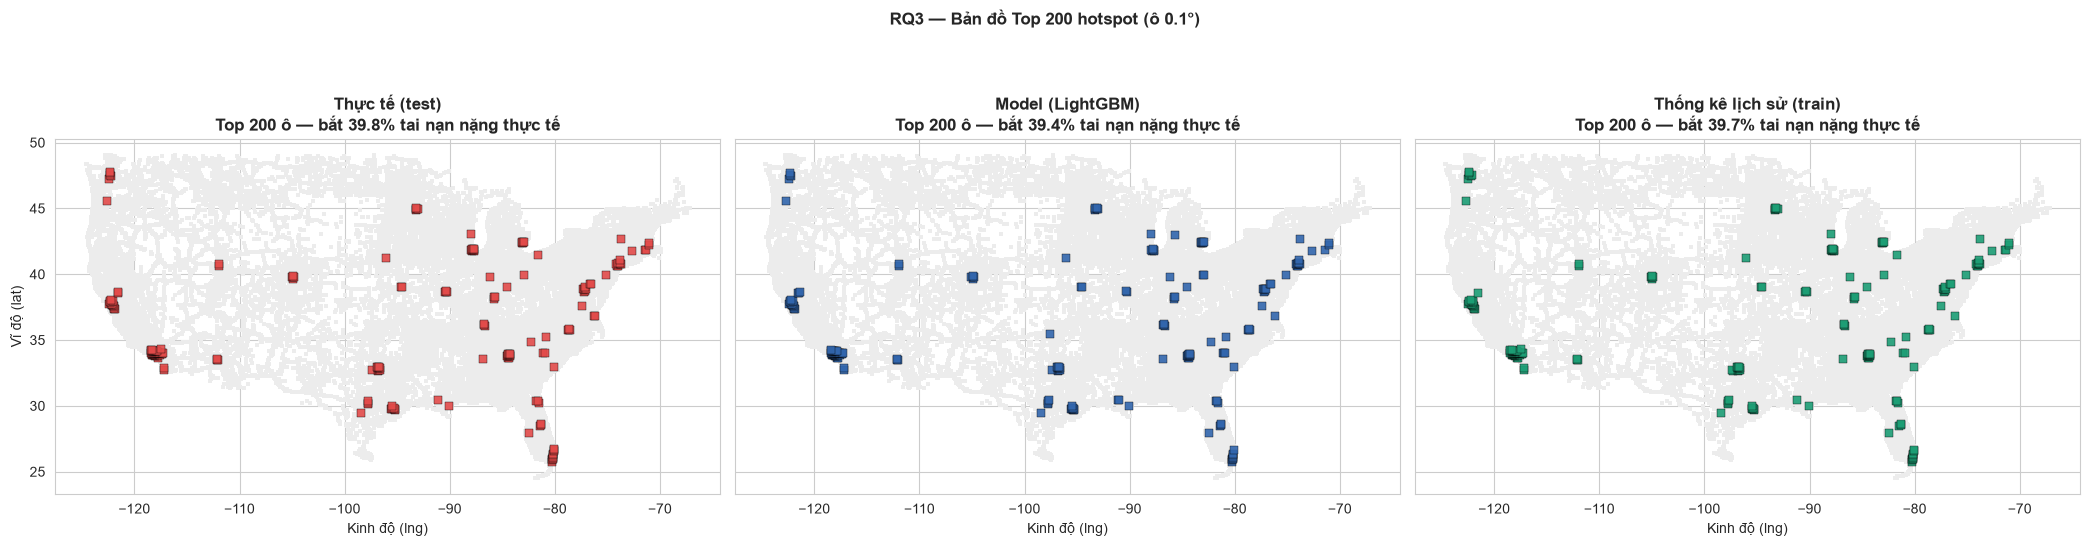

In [19]:
# ============================================
# RQ3 - Buoc 3b: Ban do TOP-K HOTSPOT cua tung phuong phap
# ============================================
def _in(cells):
    return np.isin(grid['key'].to_numpy(), cells)

m_act, m_mod, m_his = _in(H_actual), _in(H_model), _in(H_hist)

topk_panels = [
    ('Thực tế (test)',            m_act, '#E24B4A', H_actual),
    (f'Model ({BEST_MODEL})',     m_mod, '#3266ad', H_model),
    ('Thống kê lịch sử (train)',  m_his, '#1D9E75', H_hist),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 5.8), sharex=True, sharey=True)
for ax, (title, mask, color, cells) in zip(axes, topk_panels):
    ax.scatter(grid['lng_c'], grid['lat_c'], c='#ececec', s=6, marker='s', linewidths=0)
    ax.scatter(grid.loc[mask, 'lng_c'], grid.loc[mask, 'lat_c'], c=color, s=38, marker='s',
               edgecolors='black', linewidths=0.3, alpha=0.9)
    ax.set_title(f'{title}\nTop {TOP_K} ô — bắt {captured_pct(grid, cells):.1f}% tai nạn nặng thực tế')
    ax.set_xlabel('Kinh độ (lng)')
    ax.set_aspect(ASPECT)
axes[0].set_ylabel('Vĩ độ (lat)')
fig.suptitle(f'RQ3 — Bản đồ Top {TOP_K} hotspot (ô {GRID_DEG}°)', fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('rq3_topk_hotspot_maps.png', dpi=150, bbox_inches='tight')
plt.show()

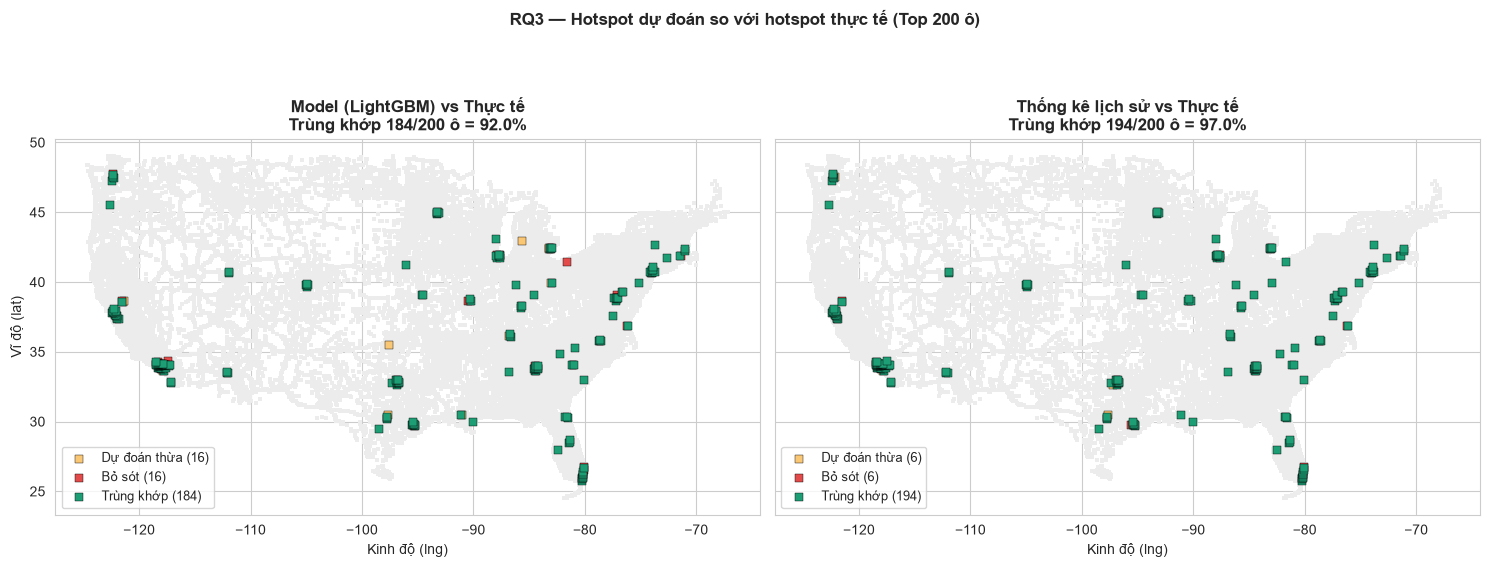

In [20]:
# ============================================
# RQ3 - Buoc 3c: Ban do TRUNG KHOP — dung / thua / bo sot so voi thuc te
# ============================================
C_HIT, C_FA, C_MISS = '#1D9E75', '#FAC775', '#E24B4A'

def overlap_panel(ax, pred_mask, title):
    hit  = pred_mask & m_act        # du doan dung: ca hai deu la hotspot
    fa   = pred_mask & ~m_act       # bao dong gia: du doan hotspot nhung thuc te khong
    miss = ~pred_mask & m_act       # bo sot: thuc te la hotspot nhung khong du doan duoc
    ax.scatter(grid['lng_c'], grid['lat_c'], c='#ececec', s=6, marker='s', linewidths=0)
    for m, c, lab in [(fa, C_FA, f'Dự đoán thừa ({fa.sum()})'),
                      (miss, C_MISS, f'Bỏ sót ({miss.sum()})'),
                      (hit, C_HIT, f'Trùng khớp ({hit.sum()})')]:
        ax.scatter(grid.loc[m, 'lng_c'], grid.loc[m, 'lat_c'], c=c, s=38, marker='s',
                   edgecolors='black', linewidths=0.3, label=lab)
    ax.set_title(f'{title}\nTrùng khớp {hit.sum()}/{TOP_K} ô = {hit.sum()/TOP_K*100:.1f}%')
    ax.set_xlabel('Kinh độ (lng)')
    ax.set_aspect(ASPECT)
    ax.legend(loc='lower left', fontsize=9, frameon=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
overlap_panel(axes[0], m_mod, f'Model ({BEST_MODEL}) vs Thực tế')
overlap_panel(axes[1], m_his, 'Thống kê lịch sử vs Thực tế')
axes[0].set_ylabel('Vĩ độ (lat)')
fig.suptitle(f'RQ3 — Hotspot dự đoán so với hotspot thực tế (Top {TOP_K} ô)', fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('rq3_overlap_maps.png', dpi=150, bbox_inches='tight')
plt.show()

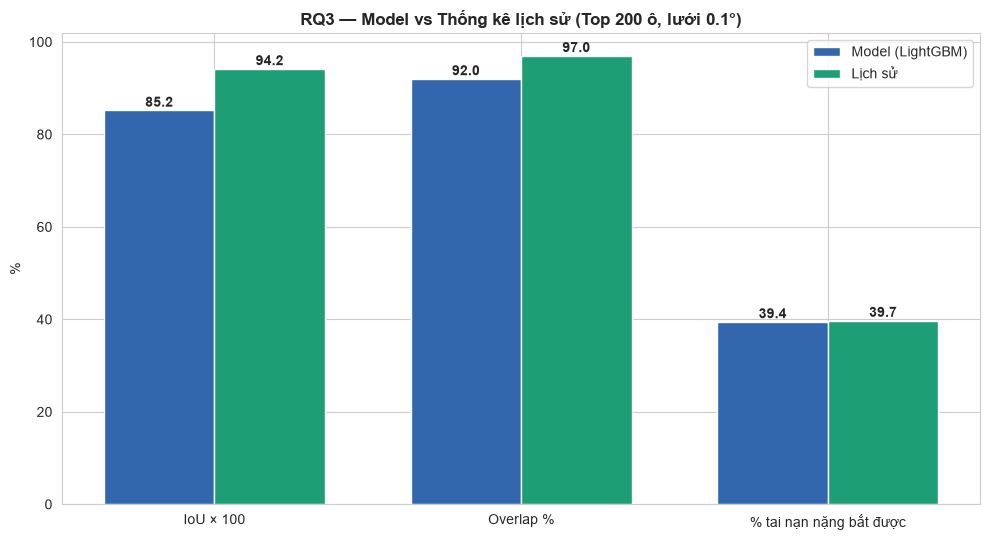

Top 10 o hotspot theo model:


,Lat,Lng,Tai nan (test),Nang that,Nang (model ky vong),Nang lich su (train)
1,34.05,-118.25,9898.0,2283.0,2997.699951,9362.0
2,33.75,-84.35,4264.0,2284.0,2683.479980,8988.0
3,40.85,-73.95,5352.0,1731.0,2258.860107,7095.0
4,33.95,-118.15,4702.0,1566.0,1912.800049,6413.0
5,33.95,-118.25,7151.0,1355.0,1755.469971,5373.0
6,34.05,-118.45,3951.0,1430.0,1739.890015,5798.0
7,34.05,-118.15,5750.0,1229.0,1720.420044,4836.0
8,25.85,-80.25,7364.0,1381.0,1691.160034,5733.0
9,33.85,-118.25,4904.0,1250.0,1678.339966,5254.0
10,34.05,-118.05,4601.0,1305.0,1625.219971,4938.0


In [21]:
# ============================================
# RQ3 - Buoc 3d: Bieu do so sanh Model vs Lich su + Top 10 o nong nhat
# ============================================
# --- Bieu do cot: 3 chi so, Model vs Lich su ---
metrics = {'IoU × 100': rq3['IoU vs thuc te'] * 100,
           'Overlap %': rq3['Overlap % vs thuc te'],
           '% tai nạn nặng bắt được': rq3['% tai nan nang bat duoc']}
labels = ['Model', 'Lịch sử']
x = np.arange(len(metrics)); w = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
for j, (lab, col) in enumerate(zip(labels, ['#3266ad', '#1D9E75'])):
    vals = [m.iloc[j] for m in metrics.values()]
    bars = ax.bar(x + (j - 0.5) * w, vals, w, label=f'{lab} ({BEST_MODEL})' if j == 0 else lab, color=col)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f'{v:.1f}', ha='center', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(list(metrics.keys()))
ax.set_ylabel('%'); ax.set_ylim(0, max(100, ax.get_ylim()[1]))
ax.set_title(f'RQ3 — Model vs Thống kê lịch sử (Top {TOP_K} ô, lưới {GRID_DEG}°)')
ax.legend()
plt.tight_layout(); plt.savefig('rq3_model_vs_history.png', dpi=150, bbox_inches='tight'); plt.show()

# --- Top 10 o nong nhat theo model (toa do tam o) ---
top10 = (grid[_in(H_model)].nlargest(10, 'exp_severe')
         [['lat_c', 'lng_c', 'n_test', 'actual_severe', 'exp_severe', 'hist_severe']]
         .rename(columns={'lat_c': 'Lat', 'lng_c': 'Lng', 'n_test': 'Tai nan (test)',
                          'actual_severe': 'Nang that', 'exp_severe': 'Nang (model ky vong)',
                          'hist_severe': 'Nang lich su (train)'})
         .round(2).reset_index(drop=True))
top10.index += 1
print('Top 10 o hotspot theo model:')
display(top10)

### Kết luận RQ3 — điền số thật từ output ở trên

Trả lời trực tiếp câu hỏi RQ3 theo mẫu:

> Với lưới **0.1°** (~11 km) và **TOP 200 ô**, bản đồ hotspot do model **LightGBM** dự đoán trùng khớp **____%** với hotspot thực tế (IoU = ____), so với **____%** (IoU = ____) của thống kê lịch sử đơn thuần — chênh lệch **____ điểm %**. Vùng hotspot của model bắt được **____%** tổng số tai nạn nghiêm trọng trong tập test.


## 11. Tổng kết — Module 2 hoàn thành (RQ1 · RQ2 · RQ3)

### RQ2 — So sánh 2 model

| Model | Cơ chế | Ghi chú kỹ thuật |
|---|---|---|
| **XGBoost** | gradient boosting | API hiện hành: `device=`, `tree_method='hist'`, early stopping trong constructor |
| **LightGBM** | leaf-wise + GOSS/EFB | categorical native |

### RQ1 — Yếu tố drive Severity
Thứ tự nhóm biến theo SHAP: **Thời gian > Vị trí > Thời tiết > Hạ tầng đường**. Hai phát hiện đáng viết nhất: (1) `year` đứng đầu → **cảnh báo data drift**, (2) hạ tầng có đèn/vạch/biển dừng **giảm** mức nghiêm trọng (OR < 0.4) — phản trực giác.

### RQ3 — Hotspot dự đoán vs lịch sử
Dựng lưới ô theo lat/lng, so **IoU / Overlap % / % tai nạn nặng bắt được** giữa hotspot của model và hotspot thống kê lịch sử.

### Phương pháp & kỹ thuật
- **Chống data leakage**: không dùng `Distance(mi)`, `End_Time`, `Severity_high`, `ID` làm feature (`Duration`, `End_Lat/Lng`, `Description` đã loại từ Module 1)
- **Input**: nạp trực tiếp `cleaned_us_accidents.parquet` / `.csv` từ Module 1 (đã xử lý missing / duplicate / outlier và feature engineering)
- **Cramér's V** + **Odds Ratio** cho RQ1
- **Class imbalance**: tempered class weight `(1/tần suất)^0.4` lúc train; đánh giá bằng Balanced Accuracy và F1 macro (không chỉ Accuracy)
- **Metric theo RQ2**: Accuracy, Balanced Accuracy, F1 macro/weighted, AUC-ROC one-vs-rest, Confusion Matrix
- **SHAP** (`TreeExplainer` trên XGBoost/LightGBM) cho RQ1
- **Grid-based hotspot + IoU/Overlap + % tai nạn nặng bắt được** cho RQ3